In [1]:
!pip install opencv-python matplotlib numpy inference-sdk


ERROR: Ignored the following yanked versions: 0.9.0, 0.9.1, 0.9.2, 0.9.3, 0.9.4, 0.9.5, 0.9.6, 0.9.7rc2, 0.9.7, 0.9.8, 0.9.9rc23, 0.9.9, 0.9.10rc3, 0.9.10, 0.9.11rc1, 0.9.11rc2, 0.9.11, 0.9.12rc1, 0.9.12rc3, 0.9.12, 0.9.13, 0.9.14, 0.9.15rc1, 0.9.15, 0.9.16, 0.9.17
ERROR: Ignored the following versions that require a different python version: 0.10.0 Requires-Python >=3.8,<3.12; 0.11.0 Requires-Python >=3.8,<3.12; 0.11.1 Requires-Python >=3.8,<3.12; 0.11.2 Requires-Python >=3.8,<3.12; 0.12.0 Requires-Python >=3.8,<3.12; 0.12.1 Requires-Python >=3.8,<3.12; 0.13.0 Requires-Python >=3.8,<3.12; 0.14.0 Requires-Python >=3.8,<3.12; 0.14.1 Requires-Python >=3.8,<3.12; 0.15.0 Requires-Python >=3.8,<3.12; 0.15.1 Requires-Python >=3.8,<3.12; 0.15.2 Requires-Python >=3.8,<3.12; 0.16.0 Requires-Python >=3.8,<3.12; 0.16.2 Requires-Python >=3.8,<3.12; 0.16.3 Requires-Python >=3.8,<3.12; 0.17.0 Requires-Python >=3.8,<3.12; 0.17.1 Requires-Python >=3.8,<3.12; 0.18.0 Requires-Python >=3.8,<3.12; 0.18.1 

In [2]:
# IMPORTS.
import cv2
import numpy as np
import matplotlib.pyplot as plt
import base64
import requests
from pathlib import Path
import json
import math
import base64
import requests
from io import BytesIO
from PIL import Image

# API STUFF.
ROBOFLOW_API_KEY = "uNmb9cMD2VA4fZBSfKKG"
WORKSPACE_ID = "michael-king-om0es"
CAR_DETECTOR_ID = "2026-f1-season-cars-qronp-2-rfdetr-medium-t1"      
TEAM_CLASSIFIER_ID = "2026-f1-season-cars-qronp-1-rfdetr-large-t1"

WORKING_DIR = Path.cwd()
DATA_DIR = WORKING_DIR / "data"
TEST_IMAGES_DIR = DATA_DIR / "pics"
DRIVER_JSON = DATA_DIR / "drivers-db.json"

In [3]:

def run_rf_detr(image_path, workspace_id, model_id, api_key):
    # Load and regenerate a clean JPEG
    image = Image.open(image_path).convert("RGB")

    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=95)
    jpeg_bytes = buffer.getvalue()

    image_b64 = base64.b64encode(jpeg_bytes).decode("utf-8")

    # Verify our Base64 locally before sending
    assert base64.b64decode(image_b64, validate=True) == jpeg_bytes

    url = f"https://serverless.roboflow.com/{workspace_id}/{model_id}"

    response = requests.post(
        url,
        params={
            "api_key": api_key,
            "image_type": "base64",
        },
        data=image_b64,
        headers={"Content-Type": "application/json"},
        timeout=120,
    )

    print("URL:", response.request.url.split("?")[0])
    print("Image bytes:", len(jpeg_bytes))
    print("Base64 characters:", len(image_b64))
    print("Response:", response.status_code, response.text)

    response.raise_for_status()
    return response.json()

In [4]:
car_detection_results = run_rf_detr(
    image_path=TEST_IMAGES_DIR / "test-me-twin.jpg",
    workspace_id=WORKSPACE_ID,
    model_id=CAR_DETECTOR_ID,
    api_key=ROBOFLOW_API_KEY
)

print(car_detection_results)

URL: https://serverless.roboflow.com/michael-king-om0es/2026-f1-season-cars-qronp-2-rfdetr-medium-t1
Image bytes: 210166
Base64 characters: 280224
Response: 200 {"inference_id":"d22fd6ba-fb78-47c1-9bfa-7f5224008f7d","time":0.1467705317772925,"image":{"width":1024,"height":684},"predictions":[{"x":565.0,"y":493.0,"width":554.0,"height":244.0,"confidence":0.8154644966125488,"class":"car","class_id":0,"detection_id":"47bd98ab-40f0-4d77-a782-f98a99017a40"},{"x":217.0,"y":140.0,"width":340.0,"height":98.0,"confidence":0.7783860564231873,"class":"car","class_id":0,"detection_id":"6d6029e7-4f81-4f2a-889b-698514540703"},{"x":548.0,"y":153.0,"width":270.0,"height":108.0,"confidence":0.5759770274162292,"class":"car","class_id":0,"detection_id":"f572a63f-1c3d-441c-96b5-a16233ae4770"},{"x":718.5,"y":213.5,"width":345.0,"height":157.0,"confidence":0.5729519128799438,"class":"car","class_id":0,"detection_id":"5cc46b64-64d0-4406-9a00-588e182ab11f"},{"x":408.5,"y":297.0,"width":361.0,"height":140.0,"c

In [5]:

def annotate_detections(image_path, results):

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(f"Could not load image: {image_path}")

    image_height, image_width = image.shape[:2]
    result_width = results["image"]["width"]
    result_height = results["image"]["height"]

    scale_x = image_width / result_width
    scale_y = image_height / result_height

    for prediction in results.get("predictions", []):

        x = prediction["x"]
        y = prediction["y"]
        
        width = prediction["width"]
        height = prediction["height"]

        x1 = round((x - width / 2) * scale_x)
        y1 = round((y - height / 2) * scale_y)
        x2 = round((x + width / 2) * scale_x)
        y2 = round((y + height / 2) * scale_y)

        # Keep coordinates inside the image.
        x1 = max(0, min(x1, image_width - 1))
        y1 = max(0, min(y1, image_height - 1))
        x2 = max(0, min(x2, image_width - 1))
        y2 = max(0, min(y2, image_height - 1))

        label = prediction.get("class", "object")
        confidence = prediction.get("confidence", 0)
        caption = f"{label} {confidence:.1%}"

        color = (0, 0, 255)  # Red in BGR
        thickness = 2

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            thickness,
        )

        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.6
        text_thickness = 2

        (text_width, text_height), baseline = cv2.getTextSize(
            caption,
            font,
            font_scale,
            text_thickness,
        )

        label_y1 = max(0, y1 - text_height - baseline - 8)

        cv2.rectangle(
            image,
            (x1, label_y1),
            (min(image_width - 1, x1 + text_width + 8), y1),
            color,
            -1,
        )

        cv2.putText(
            image,
            caption,
            (x1 + 4, max(text_height, y1 - baseline - 4)),
            font,
            font_scale,
            (255, 255, 255),
            text_thickness,
            cv2.LINE_AA,
        )

    return image

Cropping 5 cars...


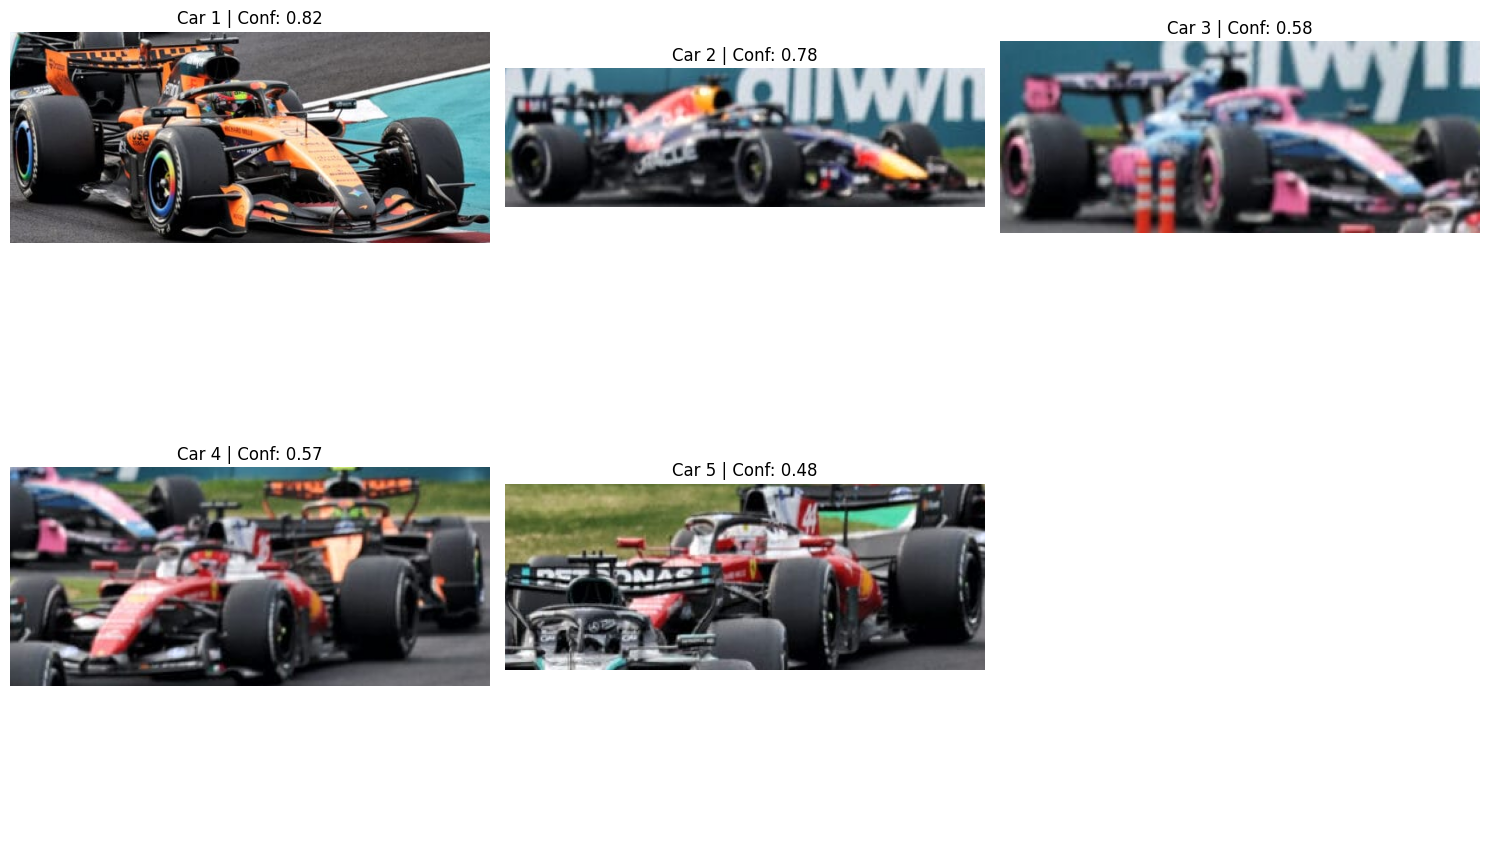

In [6]:
annotated_image = annotate_detections(TEST_IMAGES_DIR / "test-me-twin.jpg", car_detection_results)

plain_image = cv2.imread(str(TEST_IMAGES_DIR / "test-me-twin.jpg"))

# Assuming 'image_cv' is your loaded high-res image 
# and 'car_results' is the JSON returned from the detector

predictions = car_detection_results.get("predictions", [])
num_cars = len(predictions)
print(f"Cropping {num_cars} cars...")

crops = []

if num_cars > 0:
    # Calculate grid size for plotting (e.g., 3 columns)
    cols = 3
    rows = math.ceil(num_cars / cols)
    
    # Create a matplotlib figure
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten() # Flatten so we can iterate over it easily
    
    img_h, img_w, _ = annotated_image.shape

    for i, pred in enumerate(predictions):
        # 1. Convert center x,y to top-left and bottom-right coordinates
        x1 = max(0, int(pred["x"] - (pred["width"] / 2)))
        y1 = max(0, int(pred["y"] - (pred["height"] / 2)))
        x2 = min(img_w, int(pred["x"] + (pred["width"] / 2)))
        y2 = min(img_h, int(pred["y"] + (pred["height"] / 2)))
        
        # 2. Crop the array (Syntax: image[start_y:end_y, start_x:end_x])
        car_crop = plain_image[y1:y2, x1:x2]
        
        # Skip if the crop is empty (edge case protection)
        if car_crop.size == 0:
            continue
            
        # 3. Convert BGR to RGB for matplotlib
        car_crop_rgb = cv2.cvtColor(car_crop, cv2.COLOR_BGR2RGB)

        crops.append(car_crop_rgb)
        
        # 4. Plot it in the grid
        axes[i].imshow(car_crop_rgb)
        axes[i].set_title(f"Car {i+1} | Conf: {pred['confidence']:.2f}")
        axes[i].axis("off")
        
    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
        
    plt.tight_layout()
    plt.show()
else:
    print("No cars detected to crop!")

In [ ]:
from pathlib import Path
import cv2

team_api_results = []

output_dir = Path("./data/out")
output_dir.mkdir(parents=True, exist_ok=True)

for i, car_crop_rgb in enumerate(crops[:1]):
    
    # Convert the Matplotlib RGB crop back to OpenCV BGR.
    car_crop = cv2.cvtColor(
        car_crop_rgb,
        cv2.COLOR_RGB2BGR,
    )

    output_path = output_dir / f"car_{i + 1}.jpg"

    saved_success = cv2.imwrite(
        str(output_path),
        car_crop,
        [cv2.IMWRITE_JPEG_QUALITY, 95],
    )

    if not saved_success:
        print(f"Could not save car {i + 1}")
        team_api_results.append(None)
        continue

    team_result = run_rf_detr(
        image_path=output_path,
        workspace_id=WORKSPACE_ID,
        model_id=TEAM_CLASSIFIER_ID,
        api_key=ROBOFLOW_API_KEY,
    )

    team_api_results.append(team_result)

print(team_api_results)

URL: https://serverless.roboflow.com/michael-king-om0es/2026-f1-season-cars-qronp-1-rfdetr-large-t1
Image bytes: 61822
Base64 characters: 82432
Response: 200 {"inference_id":"a41da0cb-64fe-4d5a-aa3b-4cb662d223b1","time":0.2479537487961352,"image":{"width":554,"height":244},"predictions":[{"x":277.0,"y":119.0,"width":550.0,"height":238.0,"confidence":0.9785555601119995,"class":"McLaren MCL40","class_id":7,"detection_id":"dfd0670f-81b6-4f3b-8548-14d6fdf0ae1d"}]}
[{'inference_id': 'a41da0cb-64fe-4d5a-aa3b-4cb662d223b1', 'time': 0.2479537487961352, 'image': {'width': 554, 'height': 244}, 'predictions': [{'x': 277.0, 'y': 119.0, 'width': 550.0, 'height': 238.0, 'confidence': 0.9785555601119995, 'class': 'McLaren MCL40', 'class_id': 7, 'detection_id': 'dfd0670f-81b6-4f3b-8548-14d6fdf0ae1d'}]}]


McLaren MCL40: 97.9%


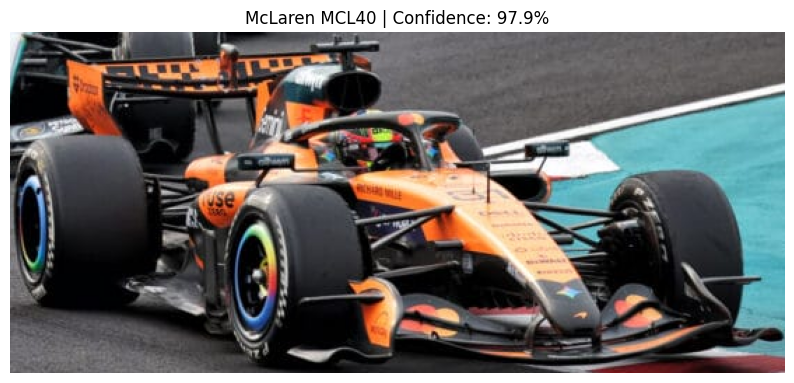

In [ ]:
result = team_api_results[0]
car_crop = crops[0]

best_prediction = max(
    result["predictions"],
    key=lambda prediction: prediction["confidence"],
)

car_model = best_prediction["class"]
confidence = best_prediction["confidence"]

plt.figure(figsize=(10, 5))
plt.imshow(car_crop)
plt.title(f"{car_model} | Confidence: {confidence:.1%}")
plt.axis("off")
plt.show()

In [25]:
def detect_tcam_color(
    tcam_crop,
    yellow_ratio_threshold=0.004,
    return_debug=False,
):
    if tcam_crop is None or tcam_crop.size == 0:
        result = "unknown"
        return (result, {}) if return_debug else result

    hsv = cv2.cvtColor(tcam_crop, cv2.COLOR_BGR2HSV)

    # Fluorescent yellow range. The lower hue excludes most orange liveries.
    lower_yellow = np.array([20, 90, 100], dtype=np.uint8)
    upper_yellow = np.array([45, 255, 255], dtype=np.uint8)

    yellow_mask = cv2.inRange(
        hsv,
        lower_yellow,
        upper_yellow,
    )

    # Remove isolated noise and connect nearby yellow pixels.
    kernel = np.ones((3, 3), dtype=np.uint8)

    yellow_mask = cv2.morphologyEx(
        yellow_mask,
        cv2.MORPH_OPEN,
        kernel,
    )
    yellow_mask = cv2.morphologyEx(
        yellow_mask,
        cv2.MORPH_CLOSE,
        kernel,
    )

    crop_area = tcam_crop.shape[0] * tcam_crop.shape[1]
    yellow_pixels = cv2.countNonZero(yellow_mask)
    yellow_ratio = yellow_pixels / crop_area

    # Require a coherent yellow region, not scattered livery pixels.
    number_of_labels, _, stats, _ = (
        cv2.connectedComponentsWithStats(yellow_mask)
    )

    if number_of_labels > 1:
        largest_yellow_region = int(
            stats[1:, cv2.CC_STAT_AREA].max()
        )
    else:
        largest_yellow_region = 0

    minimum_region_area = max(8, round(crop_area * 0.001))

    is_yellow = (
        yellow_ratio >= yellow_ratio_threshold
        and largest_yellow_region >= minimum_region_area
    )

    return "yellow" if is_yellow else "black"

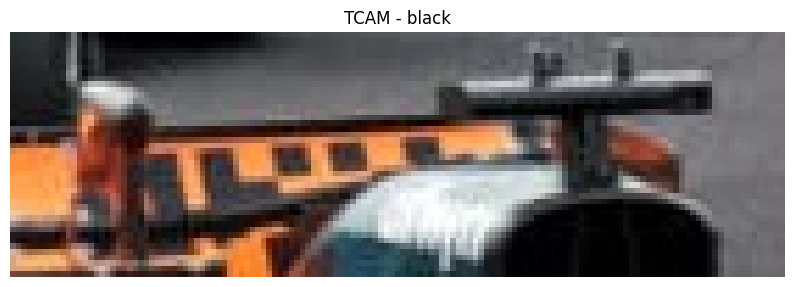

In [26]:
car_h, car_w = car_crop.shape[:2]

tcam_crop = car_crop[
    :round(car_h * 0.18),
    round(car_w * 0.25):round(car_w * 0.5),
]

tcam_color = detect_tcam_color(tcam_crop)

plt.figure(figsize=(10, 5))
plt.imshow(tcam_crop)
plt.title(f"TCAM - {tcam_color}")
plt.axis("off")
plt.show()

In [30]:
import re


TEAM_ALIASES = {
    "McLaren": [
        "mclaren",
    ],
    "Ferrari": [
        "ferrari",
    ],
    "Red Bull Racing": [
        "red bull racing",
        "red bull",
    ],
    "Mercedes": [
        "mercedes",
        "mercedes amg",
    ],
    "Aston Martin": [
        "aston martin",
    ],
    "Williams": [
        "williams",
    ],
    "Alpine": [
        "alpine",
    ],
    "Haas": [
        "haas",
    ],
    "RB": [
        "racing bulls",
        "visa cash app rb",
        "vcarb",
    ],
    "Audi": [
        "audi",
    ],
    "Cadillac": [
        "cadillac",
    ],
}


def normalize_text(value):
    """Lowercase and replace punctuation with spaces."""
    return " ".join(
        re.findall(r"[a-z0-9]+", value.casefold())
    )


def contains_phrase(text, phrase):
    """Match a normalized whole phrase, not arbitrary characters."""
    return f" {phrase} " in f" {text} "


def resolve_team(car_model, driver_db):
    normalized_model = normalize_text(car_model)

    # Include database keys themselves as aliases.
    candidates = []

    for team in driver_db:
        aliases = TEAM_ALIASES.get(team, [])
        aliases = [team, *aliases]

        for alias in aliases:
            normalized_alias = normalize_text(alias)
            candidates.append((
                normalized_alias,
                team,
            ))

    # Prefer longer, more specific aliases.
    candidates.sort(
        key=lambda item: len(item[0]),
        reverse=True,
    )

    for alias, team in candidates:
        if contains_phrase(normalized_model, alias):
            return team

    return None

def load_json(json_path):
    json_path = Path(json_path)

    with json_path.open("r", encoding="utf-8") as file:
        return json.load(file)

driver_db = load_json(DRIVER_JSON)

team = resolve_team(car_model, driver_db)

print(team)


McLaren


In [31]:
def lookup_driver(car_model, tcam_color, driver_db):
    team = resolve_team(car_model, driver_db)

    if team is None:
        return {
            "team": None,
            "tcam": tcam_color,
            "driver": "Unknown Driver",
            "number": None,
        }

    normalized_tcam = normalize_text(tcam_color)

    if normalized_tcam not in {"black", "yellow"}:
        return {
            "team": team,
            "tcam": normalized_tcam,
            "driver": "Unknown Driver",
            "number": None,
        }

    driver_record = (
        driver_db
        .get(team, {})
        .get(normalized_tcam)
    )

    if driver_record is None:
        return {
            "team": team,
            "tcam": normalized_tcam,
            "driver": "Unknown Driver",
            "number": None,
        }

    return {
        "team": team,
        "tcam": normalized_tcam,
        "driver": driver_record["driver"],
        "number": driver_record["number"],
    }

In [32]:
driver_result = lookup_driver(
    car_model,
    tcam_color,
    driver_db,
)

print(driver_result)

{'team': 'McLaren', 'tcam': 'black', 'driver': 'Lando Norris', 'number': 1}


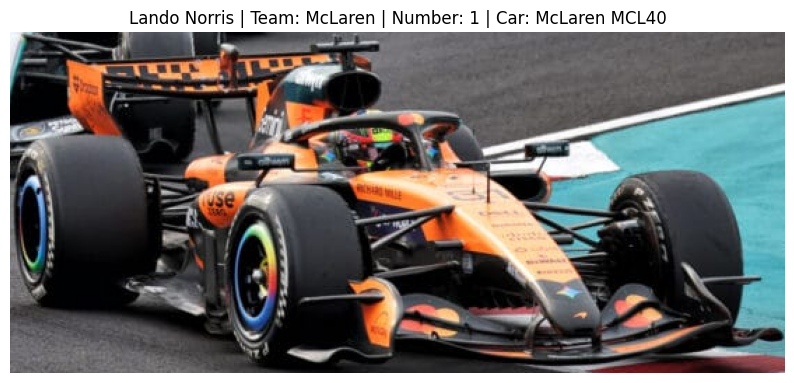

In [36]:
plt.figure(figsize=(10, 5))
plt.imshow(car_crop)
plt.title(f"{driver_result['driver']} | Team: {driver_result['team']} | Number: {driver_result['number']} | Car: {car_model}")
plt.axis("off")
plt.show()